# 概要 overview

作成したモデルに対してSHAP分析を行い、
強度に影響を及ぼす因子に関して確認する

## ライブラリ読み込み

In [24]:
import pandas as pd
from pathlib import Path
import joblib

import shap

RANDOM_STATE=42

## データの読み込み

データの読み込み
PandasDataFrameで渡したいので、関数使わず読み込み。
（nparrayはSHAP分析で項目名が出てこない）

In [25]:
data_path =  "data/Concrete_Data.xlsx"

df = pd.read_excel(data_path)

# 項目名簡略化のため、()内の記述削除
df.columns = df.columns.str.replace(r"\s*\([^)]*\)", "", regex=True)


X = df.drop(columns=["Concrete compressive strength "])
Y = df["Concrete compressive strength "]

## モデルの読み込み

学習済みモデルを読み込む。
今回は、LightGBMモデル

In [26]:
# モデルの読み込み
saved_data = joblib.load("results/GBDT/GBDT_model.pkl")

# 注：辞書型になっている。"model"キーにmodelが入っている。
print(saved_data.keys())

# 辞書の中からモデル本体を取り出す
model = saved_data["model"]

dict_keys(['model', 'input_dim', 'output_dim'])


## SHAP分析



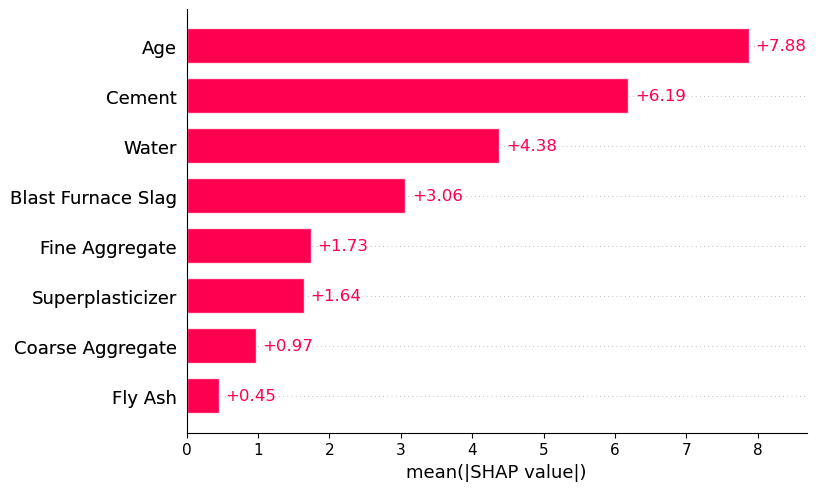

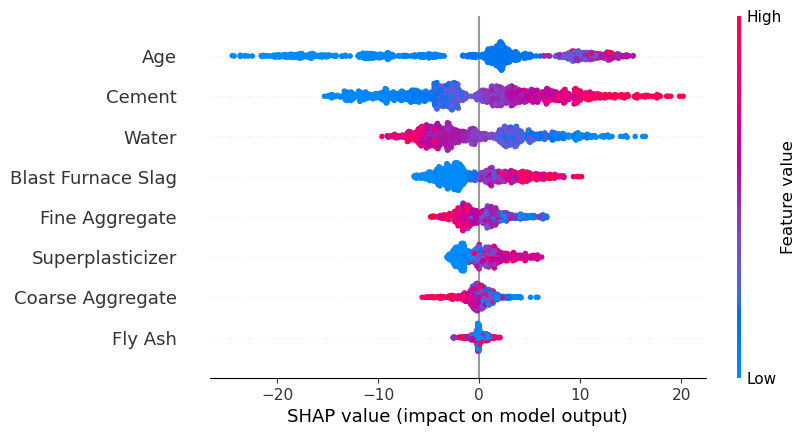

In [27]:
# 検証データから計算用にサンプリング（重すぎる場合は n=1000 などに調整）
# X_shap = X_valid.sample(n=min(2000, len(X_valid)), random_state=RANDOM_STATE)

# TreeExplainer を作成（LGBMRegressor / RandomForestRegressor どちらでも利用可能）
explainer = shap.TreeExplainer(model)
shap_exp = explainer(X)

# 1) Bar plot（全体ランキング）
shap.plots.bar(shap_exp, max_display=15)

# 2) Beeswarm plot（影響の向きと分布）
shap.plots.beeswarm(shap_exp, max_display=15)


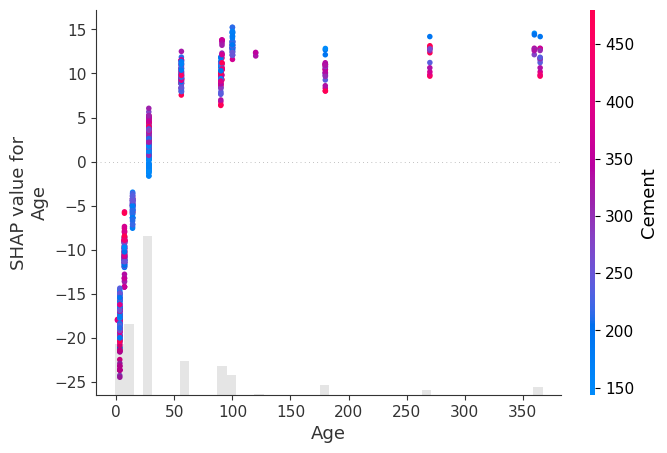

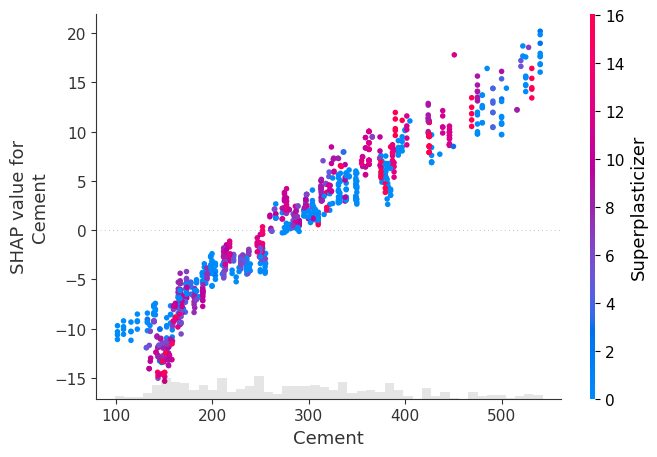

In [28]:

# Dependence plot(scatter)：最上位の特徴量について、相互作用の強い列を自動色分けで表示
# 注:Explanationオブジェクトの場合は"scatter"

feature = "Age"  # 文字列で指定
shap.plots.scatter(shap_exp[:, feature], color=shap_exp)

feature = "Cement"  # 文字列で指定
shap.plots.scatter(shap_exp[:, feature], color=shap_exp)


# 分析・考察

bar_plotおよびBeeswarmの図より
"Age"が強度に大きく影響を及ぼしている。
depandanceplotをみると、対数関数のような変化をしている。
　⇒log("Age")により増加曲線を抑制し、細やかな変化をとらえやすい可能性あり

また、dependence_plotより、"Age"と"Cement"の関係が深い
　⇒log("Age")*"Cement"　などの特徴量エンジニアリングが有効な可能あり

同じくdependence_plotより、"Cement"と"Superplasticizer"の関係が深い
　⇒Superplasticizer=減水剤＝添加剤であることから
　　"Superplasticizer"/"Cement"(添加比率)などの特徴量エンジニアリングが有効な可能あり

